# **Unsupervised Machine Learning - Final Project**
## Customer segmentation for a telecom provider

**Author:** Omar Essam  |  **Course:** IBM Unsupervised Machine Learning

The notebook behind the final report. It segments the customers of IBM's *Telco Customer Churn* sample data with
clustering, compares five model variations (two feature sets and four algorithms), uses PCA for dimensionality
reduction and visualisation, profiles the recommended segments, and tests whether segment-specific churn models beat
one global model. Every figure and table in the report is written to `figures/` and `results/` from here.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, linkage, set_link_color_palette
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score, roc_auc_score,
                             silhouette_score)
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore', category=FutureWarning)
rs = 123
FIG, RES = Path('figures'), Path('results')
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)

BLUE, ORANGE, GRAY, INK, MUTED, GRID = '#2a78d6', '#eb6834', '#b4b2aa', '#262626', '#898781', '#e1e0d9'
SEGMENT_COLORS = ['#eb6834', '#eda100', '#2a78d6', '#1baf7a', '#6250d6']  # ordered from highest to lowest churn
plt.rcParams.update({'font.family': 'Calibri', 'font.size': 14, 'legend.fontsize': 12, 'axes.edgecolor': '#c3c2b7',
                     'axes.labelcolor': INK, 'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
                     'axes.axisbelow': True, 'axes.titlesize': 15, 'axes.titleweight': 'bold', 'axes.titlecolor': INK,
                     'savefig.dpi': 200, 'savefig.bbox': 'tight'})

## 1. Load and clean the data

In [2]:
raw = pd.read_csv('data/Telco-Customer-Churn.csv')
df = raw.copy()
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print('blank TotalCharges:', df['TotalCharges'].isna().sum(), '- tenure of those rows:', df.loc[df['TotalCharges'].isna(), 'tenure'].unique())
df['TotalCharges'] = df['TotalCharges'].fillna(0.0)   # new customers, not billed yet
df['Churn'] = (df['Churn'] == 'Yes').astype(int)
print(raw.shape, '| duplicate ids:', df['customerID'].duplicated().sum(), '| other missing values:', int(df.isna().sum().sum()))
df.head()

blank TotalCharges: 11 - tenure of those rows: [0]
(7043, 21) | duplicate ids: 0 | other missing values: 0


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


## 2. Exploration

The behaviour of a customer - how long they have stayed, how committed they are, what they buy and what they pay - is
spread unevenly: tenure and monthly charges are multi-modal, which hints at distinct groups of customers.

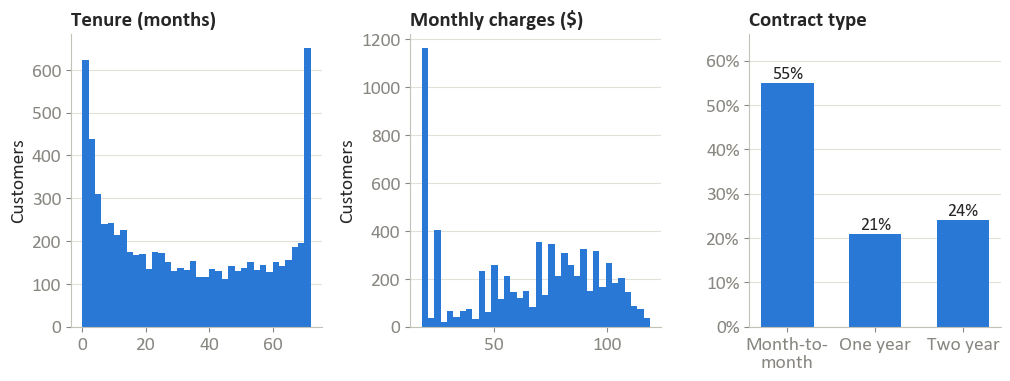

,tenure,MonthlyCharges,TotalCharges
count,7043.0,7043.0,7043.0
mean,32.4,64.8,2279.7
std,24.6,30.1,2266.8
min,0.0,18.2,0.0
25%,9.0,35.5,398.6
50%,29.0,70.4,1394.6
75%,55.0,89.8,3786.6
max,72.0,118.8,8684.8


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), gridspec_kw={'wspace': 0.35})
axes[0].hist(df['tenure'], bins=36, color=BLUE)
axes[0].set_title('Tenure (months)', loc='left')
axes[1].hist(df['MonthlyCharges'], bins=36, color=BLUE)
axes[1].set_title('Monthly charges ($)', loc='left')
mix = df['Contract'].value_counts(normalize=True).reindex(['Month-to-month', 'One year', 'Two year'])
axes[2].bar(['Month-to-\nmonth', 'One year', 'Two year'], mix.values, color=BLUE, width=0.6)
for x, v in enumerate(mix.values):
    axes[2].text(x, v + 0.01, f'{v:.0%}', ha='center', color=INK, fontsize=13)
axes[2].set_title('Contract type', loc='left')
axes[2].set_ylim(0, 0.66)
axes[2].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
for ax in axes[:2]:
    ax.set_ylabel('Customers')
for ax in axes:
    ax.grid(axis='x', visible=False)
plt.savefig(FIG / 'fig1_exploration.png')
plt.show()
df[['tenure', 'MonthlyCharges', 'TotalCharges']].describe().round(1)

## 3. Feature preparation: two candidate feature sets

* **Raw service profile (18 features):** tenure, contract length and every service, billing and household flag
  one by one. Many binary columns make distances noisy, so this set is clustered on its PCA components.
* **Engineered behavioural profile (6 features):** tenure, contract length in months, monthly charges, the number of
  protection add-ons (security, backup, device protection, tech support), the number of streaming services, and a
  fiber flag. Demographics, billing and payment are kept out of the clustering on purpose and used afterwards to
  describe the segments.

Churn is never used to build the clusters; it is only used to judge whether the segments are useful.
`TotalCharges` is left out of both sets because it is essentially tenure x monthly charges.

In [4]:
protection = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport']
streaming = ['StreamingTV', 'StreamingMovies']
contract_months = df['Contract'].map({'Month-to-month': 0, 'One year': 12, 'Two year': 24})

raw_features = pd.DataFrame({'tenure': df['tenure'], 'ContractMonths': contract_months,
                             'Fiber': (df['InternetService'] == 'Fiber optic').astype(int),
                             'DSL': (df['InternetService'] == 'DSL').astype(int),
                             'PhoneService': (df['PhoneService'] == 'Yes').astype(int),
                             'MultipleLines': (df['MultipleLines'] == 'Yes').astype(int)})
for col in protection + streaming:
    raw_features[col] = (df[col] == 'Yes').astype(int)
raw_features['PaperlessBilling'] = (df['PaperlessBilling'] == 'Yes').astype(int)
raw_features['AutoPay'] = df['PaymentMethod'].str.contains('automatic').astype(int)
raw_features['ElectronicCheck'] = (df['PaymentMethod'] == 'Electronic check').astype(int)
raw_features['SeniorCitizen'] = df['SeniorCitizen']
raw_features['Partner'] = (df['Partner'] == 'Yes').astype(int)
raw_features['Dependents'] = (df['Dependents'] == 'Yes').astype(int)

behaviour = pd.DataFrame({'tenure': df['tenure'], 'ContractMonths': contract_months, 'MonthlyCharges': df['MonthlyCharges'],
                          'ProtectionServices': (df[protection] == 'Yes').sum(axis=1),
                          'StreamingServices': (df[streaming] == 'Yes').sum(axis=1),
                          'Fiber': (df['InternetService'] == 'Fiber optic').astype(int)})
X_raw = StandardScaler().fit_transform(raw_features)
X = StandardScaler().fit_transform(behaviour)
print('raw features:', raw_features.shape[1], '| behavioural features:', behaviour.shape[1])
behaviour.corr().round(2)

raw features: 18 | behavioural features: 6


,tenure,ContractMonths,MonthlyCharges,ProtectionServices,StreamingServices,Fiber
tenure,1.00,0.67,0.25,0.50,0.32,0.02
ContractMonths,0.67,1.00,-0.07,0.33,0.12,-0.25
MonthlyCharges,0.25,-0.07,1.00,0.56,0.72,0.79
ProtectionServices,0.50,0.33,0.56,1.00,0.47,0.11
StreamingServices,0.32,0.12,0.72,0.47,1.00,0.37
Fiber,0.02,-0.25,0.79,0.11,0.37,1.00


## 4. Dimensionality reduction with PCA

PCA on the 18 raw features shows how spread out the information is; the 80%-variance components are what K-means
clusters in variation 1. PCA on the 6 behavioural features gives the 2-D map used to visualise the segments.

In [5]:
pca_raw = PCA().fit(X_raw)
cum_raw = np.cumsum(pca_raw.explained_variance_ratio_)
n80 = int(np.argmax(cum_raw >= 0.8) + 1)
Z_raw = PCA(n_components=n80, random_state=rs).fit_transform(X_raw)

pca_beh = PCA().fit(X)
loadings = pd.DataFrame(pca_beh.components_[:3].T, index=behaviour.columns, columns=['PC1', 'PC2', 'PC3'])
pca_table = pd.DataFrame({'component': np.arange(1, len(cum_raw) + 1), 'raw_variance': pca_raw.explained_variance_ratio_,
                          'raw_cumulative': cum_raw})
pca_table.to_csv(RES / 'pca_raw_variance.csv', index=False)
pd.DataFrame({'component': np.arange(1, 7), 'variance': pca_beh.explained_variance_ratio_,
              'cumulative': np.cumsum(pca_beh.explained_variance_ratio_)}).to_csv(RES / 'pca_behaviour_variance.csv', index=False)
loadings.to_csv(RES / 'pca_behaviour_loadings.csv', index_label='feature')
print(f'raw features: {n80} components keep {cum_raw[n80 - 1]:.1%} of the variance (first 3: {np.round(pca_raw.explained_variance_ratio_[:3], 3)})')
print('behavioural features, explained variance:', np.round(pca_beh.explained_variance_ratio_, 3))
loadings.round(2)

raw features: 10 components keep 81.1% of the variance (first 3: [0.204 0.159 0.105])
behavioural features, explained variance: [0.463 0.307 0.101 0.077 0.045 0.007]


,PC1,PC2,PC3
tenure,0.36,0.48,-0.36
ContractMonths,0.18,0.62,-0.33
MonthlyCharges,0.53,-0.31,-0.02
ProtectionServices,0.45,0.20,0.59
StreamingServices,0.48,-0.09,0.27
Fiber,0.34,-0.48,-0.58


## 5. Choosing the number of clusters

best silhouette (k >= 3) = 0.367; smallest k within 0.005 of it: k = 5


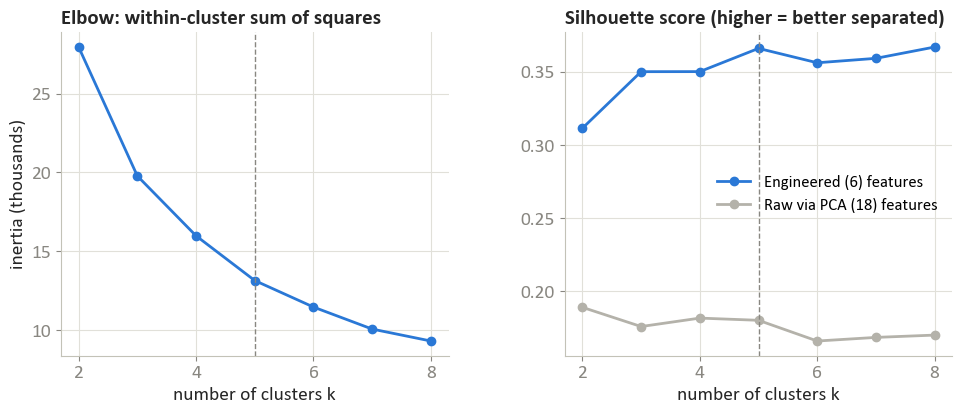

features,Engineered (6),Raw via PCA (18)
k,,
2,0.311,0.189
3,0.350,0.176
4,0.350,0.182
5,0.366,0.180
6,0.356,0.166
7,0.359,0.168
8,0.367,0.170


In [6]:
rows = []
for k in range(2, 9):
    for name, data in [('Engineered (6)', X), ('Raw via PCA (18)', Z_raw)]:
        km = KMeans(n_clusters=k, n_init=10, random_state=rs).fit(data)
        rows.append({'features': name, 'k': k, 'inertia': km.inertia_, 'silhouette': silhouette_score(data, km.labels_),
                     'davies_bouldin': davies_bouldin_score(data, km.labels_)})
kselect = pd.DataFrame(rows)
kselect.to_csv(RES / 'k_selection.csv', index=False)

eng = kselect[kselect['features'] == 'Engineered (6)']
# silhouette plateaus for k >= 3, so take the most parsimonious k within 0.005 of the best score
best_sil = eng[eng['k'] >= 3]['silhouette'].max()
K = int(eng[(eng['k'] >= 3) & (eng['silhouette'] >= best_sil - 0.005)]['k'].min())
print(f'best silhouette (k >= 3) = {best_sil:.3f}; smallest k within 0.005 of it: k = {K}')

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), gridspec_kw={'wspace': 0.3})
axes[0].plot(eng['k'], eng['inertia'] / 1000, '-o', color=BLUE, linewidth=2)
axes[0].axvline(K, color=MUTED, linestyle='--', linewidth=1)
axes[0].set_title('Elbow: within-cluster sum of squares', loc='left')
axes[0].set_xlabel('number of clusters k')
axes[0].set_ylabel('inertia (thousands)')
for name, color in [('Engineered (6)', BLUE), ('Raw via PCA (18)', GRAY)]:
    part = kselect[kselect['features'] == name]
    axes[1].plot(part['k'], part['silhouette'], '-o', color=color, linewidth=2, label=f'{name} features')
axes[1].axvline(K, color=MUTED, linestyle='--', linewidth=1)
axes[1].set_title('Silhouette score (higher = better separated)', loc='left')
axes[1].set_xlabel('number of clusters k')
axes[1].legend(frameon=False, loc='center right')
plt.savefig(FIG / 'fig2_choose_k.png')
plt.show()
kselect.pivot(index='k', columns='features', values='silhouette').round(3)

## 6. Five model variations

All five group the same 7,043 customers. They are compared on internal quality (silhouette, Davies-Bouldin,
Calinski-Harabasz), on how balanced the segment sizes are, on stability (agreement between the full fit and fits on
10 random 80% subsamples, measured with the adjusted Rand index), and on business separation (how different the churn
rates of the segments are - churn was not used to build them).

In [7]:
def stability(make, data, predict=True, runs=10):
    full = make(0).fit(data)
    base = full.labels_ if hasattr(full, 'labels_') else full.predict(data)
    rng = np.random.default_rng(rs)
    scores = []
    for s in range(1, runs + 1):
        idx = rng.choice(len(data), int(0.8 * len(data)), replace=False)
        model = make(s).fit(data[idx])
        if predict:
            scores.append(adjusted_rand_score(base, model.predict(data)))
        else:  # no predict(): compare on the subsample only
            scores.append(adjusted_rand_score(base[idx], model.labels_))
    return base, float(np.mean(scores))

variations = {
    'K-means, raw features via PCA': (lambda s: KMeans(n_clusters=K, n_init=10, random_state=rs + s), Z_raw, True),
    'K-means, engineered features': (lambda s: KMeans(n_clusters=K, n_init=10, random_state=rs + s), X, True),
    'Hierarchical (Ward), engineered features': (lambda s: AgglomerativeClustering(n_clusters=K, linkage='ward'), X, False),
    'Gaussian mixture, engineered features': (lambda s: GaussianMixture(n_components=K, covariance_type='full', n_init=3, random_state=rs + s), X, True),
}
labels, rows = {}, []
for name, (make, data, can_predict) in variations.items():
    lab, stab = stability(make, data, can_predict)
    labels[name] = lab
    churn_by = df['Churn'].groupby(lab).mean()
    rows.append({'model': name, 'clusters': len(set(lab)), 'noise_share': 0.0, 'silhouette': silhouette_score(data, lab),
                 'davies_bouldin': davies_bouldin_score(data, lab), 'calinski_harabasz': calinski_harabasz_score(data, lab),
                 'smallest_share': np.bincount(lab).min() / len(lab), 'stability_ari': stab,
                 'churn_min': churn_by.min(), 'churn_max': churn_by.max()})

# DBSCAN: eps from the knee of the 12-nearest-neighbour distance curve
dist = np.sort(NearestNeighbors(n_neighbors=12).fit(X).kneighbors(X)[0][:, -1])
eps = float(np.quantile(dist, 0.95))
db = DBSCAN(eps=eps, min_samples=12).fit_predict(X)
core = db != -1
churn_by = df.loc[core, 'Churn'].groupby(db[core]).mean()
rows.append({'model': 'DBSCAN, engineered features', 'clusters': len(set(db[core])), 'noise_share': float((~core).mean()),
             'silhouette': silhouette_score(X[core], db[core]), 'davies_bouldin': davies_bouldin_score(X[core], db[core]),
             'calinski_harabasz': calinski_harabasz_score(X[core], db[core]), 'smallest_share': np.bincount(db[core]).min() / len(db),
             'stability_ari': np.nan, 'churn_min': churn_by.min(), 'churn_max': churn_by.max()})
comparison = pd.DataFrame(rows)
comparison['eps'] = [np.nan] * 4 + [eps]
comparison.to_csv(RES / 'model_comparison.csv', index=False)
print(f'DBSCAN eps = {eps:.2f}: {len(set(db[core]))} clusters, {(~core).mean():.1%} noise')
comparison.round(3)

DBSCAN eps = 0.80: 19 clusters, 1.3% noise


,model,clusters,noise_share,silhouette,davies_bouldin,calinski_harabasz,smallest_share,stability_ari,churn_min,churn_max,eps
0,"K-means, raw features via PCA",5,0.000,0.180,1.788,1234.648,0.150,0.989,0.050,0.579,NaN
1,"K-means, engineered features",5,0.000,0.366,1.065,3895.833,0.135,0.991,0.014,0.561,NaN
2,"Hierarchical (Ward), engineered features",5,0.000,0.338,1.107,3448.615,0.142,0.788,0.017,0.546,NaN
3,"Gaussian mixture, engineered features",5,0.000,0.285,1.246,3006.040,0.137,0.954,0.054,0.546,NaN
4,"DBSCAN, engineered features",19,0.013,0.299,1.420,1831.366,0.004,NaN,0.008,0.576,0.8


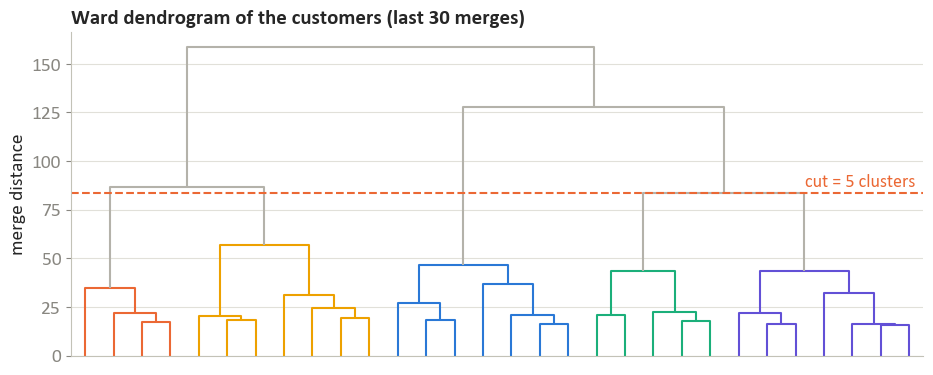

,merge_distance_last10
0,158.4
1,128.0
2,86.7
3,83.5
4,56.6
5,46.8
6,43.7
7,43.6
8,36.9
9,34.9


In [8]:
# Dendrogram of the Ward hierarchy (truncated to the last 30 merges)
Z_link = linkage(X, method='ward')
set_link_color_palette(SEGMENT_COLORS)
fig, ax = plt.subplots(figsize=(11, 4.2))
dendrogram(Z_link, truncate_mode='lastp', p=30, color_threshold=Z_link[-(K - 1), 2], above_threshold_color=GRAY,
           no_labels=True, ax=ax)
ax.axhline(Z_link[-(K - 1), 2], color=ORANGE, linestyle='--', linewidth=1.5)
ax.text(ax.get_xlim()[1] * 0.99, Z_link[-(K - 1), 2] * 1.04, f'cut = {K} clusters', ha='right', color=ORANGE, fontsize=13)
ax.set_title('Ward dendrogram of the customers (last 30 merges)', loc='left')
ax.set_ylabel('merge distance')
ax.grid(axis='x', visible=False)
plt.savefig(FIG / 'fig3_dendrogram.png')
plt.show()
pd.DataFrame({'merge_distance_last10': Z_link[-10:, 2][::-1]}).round(1)

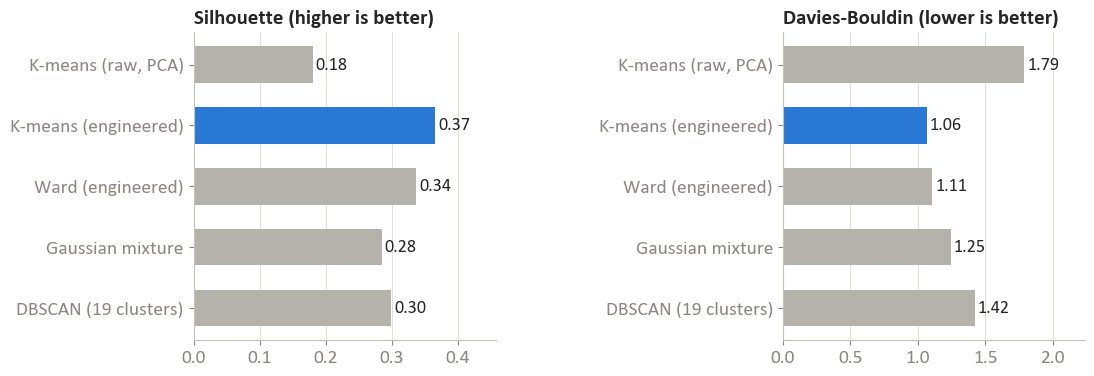

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.0), gridspec_kw={'wspace': 0.95})
short = {'K-means, raw features via PCA': 'K-means (raw, PCA)', 'K-means, engineered features': 'K-means (engineered)',
         'Hierarchical (Ward), engineered features': 'Ward (engineered)', 'Gaussian mixture, engineered features': 'Gaussian mixture',
         'DBSCAN, engineered features': f"DBSCAN ({int(comparison.iloc[-1]['clusters'])} clusters)"}
order = comparison.iloc[::-1]
names = [short[m] for m in order['model']]
best = 'K-means, engineered features'
colors = [BLUE if m == best else GRAY for m in order['model']]
axes[0].barh(names, order['silhouette'], color=colors, height=0.6)
for y, v in enumerate(order['silhouette']):
    axes[0].text(v + 0.005, y, f'{v:.2f}', va='center', color=INK, fontsize=13)
axes[0].set_title('Silhouette (higher is better)', loc='left')
axes[0].set_xlim(0, max(order['silhouette']) * 1.25)
axes[1].barh(names, order['davies_bouldin'], color=colors, height=0.6)
for y, v in enumerate(order['davies_bouldin']):
    axes[1].text(v + 0.02, y, f'{v:.2f}', va='center', color=INK, fontsize=13)
axes[1].set_title('Davies-Bouldin (lower is better)', loc='left')
axes[1].set_xlim(0, max(order['davies_bouldin']) * 1.25)
for ax in axes:
    ax.grid(axis='y', visible=False)
plt.savefig(FIG / 'fig4_model_comparison.png')
plt.show()

## 7. Profile the recommended segmentation (K-means on the engineered features)

In [10]:
segment = labels['K-means, engineered features']
prof = behaviour.assign(segment=segment).groupby('segment').mean()
extra = pd.DataFrame({'NoInternet': (df['InternetService'] == 'No').astype(int), 'SeniorCitizen': df['SeniorCitizen'],
                      'ElectronicCheck': (df['PaymentMethod'] == 'Electronic check').astype(int),
                      'AutoPay': df['PaymentMethod'].str.contains('automatic').astype(int),
                      'Family': ((df['Partner'] == 'Yes') | (df['Dependents'] == 'Yes')).astype(int), 'Churn': df['Churn']})
prof = prof.join(extra.assign(segment=segment).groupby('segment').mean())
prof.insert(0, 'customers', np.bincount(segment))
prof.insert(1, 'share', prof['customers'] / len(df))
prof['revenue_share'] = df['MonthlyCharges'].groupby(segment).sum() / df['MonthlyCharges'].sum()
prof['churned_revenue_share'] = (df['MonthlyCharges'] * df['Churn']).groupby(segment).sum() / (df['MonthlyCharges'] * df['Churn']).sum()

def name_segment(r):
    if r['NoInternet'] > 0.5:
        return 'Phone-only veterans'
    if r['Fiber'] > 0.5 and r['tenure'] < 30:
        return 'Fiber newcomers'
    if r['Fiber'] > 0.5:
        return 'Premium fiber loyalists'
    if r['ProtectionServices'] > 2:
        return 'Loyal DSL bundlers'
    return 'Budget newcomers'

prof['name'] = prof.apply(name_segment, axis=1)
assert prof['name'].is_unique, prof['name']
prof = prof.sort_values('Churn', ascending=False)
prof.to_csv(RES / 'segment_profiles.csv', index_label='segment')
prof.round(2)

,customers,share,tenure,ContractMonths,MonthlyCharges,ProtectionServices,StreamingServices,Fiber,NoInternet,SeniorCitizen,ElectronicCheck,AutoPay,Family,Churn,revenue_share,churned_revenue_share,name
segment,,,,,,,,,,,,,,,,,
0,1909,0.27,17.48,0.38,84.69,0.78,0.82,1.0,0.00,0.29,0.61,0.28,0.40,0.56,0.35,0.65,Fiber newcomers
4,1868,0.27,12.23,1.53,38.87,0.66,0.26,0.0,0.35,0.08,0.28,0.29,0.39,0.26,0.16,0.14,Budget newcomers
2,1184,0.17,57.75,13.49,102.54,2.46,1.64,1.0,0.00,0.24,0.36,0.59,0.70,0.19,0.27,0.17,Premium fiber loyalists
1,1128,0.16,52.50,17.14,69.25,2.83,1.28,0.0,0.00,0.10,0.17,0.66,0.70,0.06,0.17,0.03,Loyal DSL bundlers
3,954,0.14,46.32,20.42,23.41,0.10,0.01,0.0,0.92,0.05,0.05,0.57,0.68,0.01,0.05,0.00,Phone-only veterans


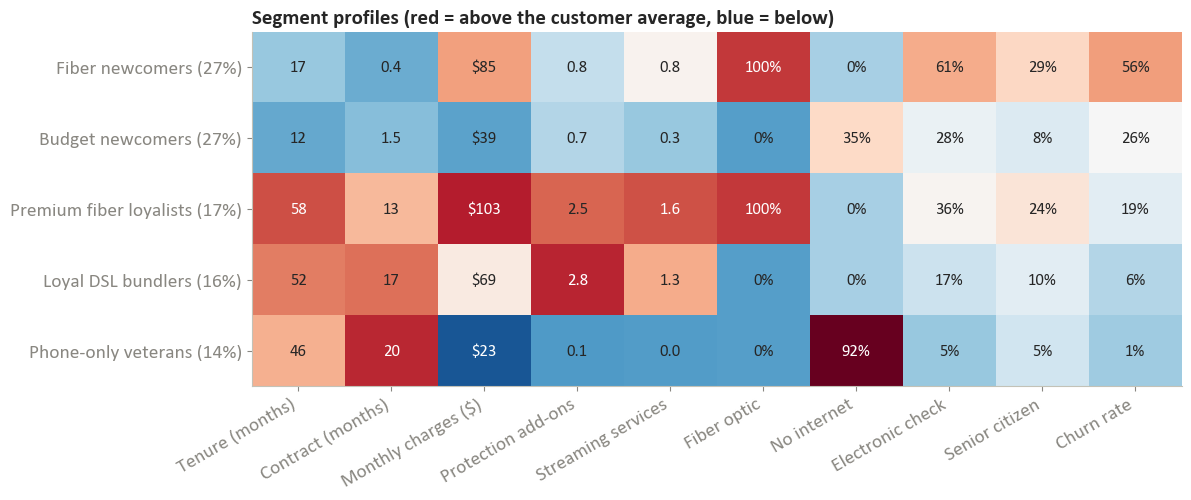

In [11]:
features_shown = ['tenure', 'ContractMonths', 'MonthlyCharges', 'ProtectionServices', 'StreamingServices', 'Fiber',
                  'NoInternet', 'ElectronicCheck', 'SeniorCitizen', 'Churn']
labels_shown = ['Tenure (months)', 'Contract (months)', 'Monthly charges ($)', 'Protection add-ons', 'Streaming services',
                'Fiber optic', 'No internet', 'Electronic check', 'Senior citizen', 'Churn rate']
values = prof[features_shown]
overall = pd.concat([behaviour, extra], axis=1)[features_shown].mean()
z = (values - overall) / pd.concat([behaviour, extra], axis=1)[features_shown].std()
fig, ax = plt.subplots(figsize=(12, 4.6))
im = ax.imshow(z.values, cmap='RdBu_r', vmin=-1.6, vmax=1.6, aspect='auto')
for i in range(values.shape[0]):
    for j, f in enumerate(features_shown):
        v = values.iloc[i, j]
        text = f'{v:.0%}' if f in ('Fiber', 'NoInternet', 'ElectronicCheck', 'SeniorCitizen', 'Churn') else (f'${v:.0f}' if f == 'MonthlyCharges' else f'{v:.1f}' if v < 10 else f'{v:.0f}')
        ax.text(j, i, text, ha='center', va='center', fontsize=12, color='white' if abs(z.iloc[i, j]) > 1.0 else INK)
ax.set_xticks(range(len(features_shown)), labels_shown, rotation=30, ha='right')
ax.set_yticks(range(len(prof)), [f"{n} ({s:.0%})" for n, s in zip(prof['name'], prof['share'])])
ax.grid(False)
ax.set_title('Segment profiles (red = above the customer average, blue = below)', loc='left')
plt.savefig(FIG / 'fig5_segment_profiles.png')
plt.show()

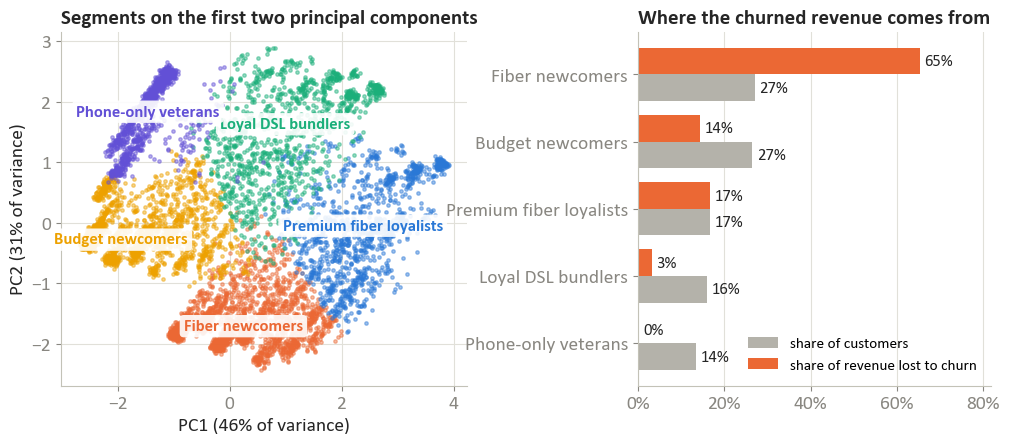

In [12]:
pc = PCA(n_components=2, random_state=rs).fit(X)
xy = pc.transform(X)
order_ids = list(prof.index)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={'width_ratios': [1.15, 1], 'wspace': 0.45})
ax = axes[0]
rng = np.random.default_rng(rs)
jitter = rng.normal(0, 0.04, xy.shape)
for rank, seg_id in enumerate(order_ids):
    m = segment == seg_id
    ax.scatter(xy[m, 0] + jitter[m, 0], xy[m, 1] + jitter[m, 1], s=6, alpha=0.45, color=SEGMENT_COLORS[rank])
for rank, seg_id in enumerate(order_ids):
    m = segment == seg_id
    ax.text(np.median(xy[m, 0]), np.median(xy[m, 1]), prof.loc[seg_id, 'name'], ha='center', va='center', fontsize=12,
            fontweight='bold', color=SEGMENT_COLORS[rank], bbox=dict(boxstyle='round,pad=0.25', fc='white', ec='none', alpha=0.9))
ax.set_xlabel(f'PC1 ({pc.explained_variance_ratio_[0]:.0%} of variance)')
ax.set_ylabel(f'PC2 ({pc.explained_variance_ratio_[1]:.0%} of variance)')
ax.set_title('Segments on the first two principal components', loc='left')
ax = axes[1]
y = np.arange(len(prof))
ax.barh(y + 0.2, prof['share'], height=0.4, color=GRAY, label='share of customers')
ax.barh(y - 0.2, prof['churned_revenue_share'], height=0.4, color=ORANGE, label='share of revenue lost to churn')
for i, (s, c) in enumerate(zip(prof['share'], prof['churned_revenue_share'])):
    ax.text(s + 0.01, i + 0.2, f'{s:.0%}', va='center', fontsize=12, color=INK)
    ax.text(c + 0.01, i - 0.2, f'{c:.0%}', va='center', fontsize=12, color=INK)
ax.set_yticks(y, prof['name'])
ax.invert_yaxis()
ax.set_xlim(0, max(prof['churned_revenue_share'].max(), prof['share'].max()) * 1.25)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set_title('Where the churned revenue comes from', loc='left')
ax.legend(frameon=False, fontsize=11, loc='lower right')
ax.grid(axis='y', visible=False)
plt.savefig(FIG / 'fig6_segments_map_revenue.png')
plt.show()

## 8. Optional: do segment-specific churn models beat one global model?

Same stratified 80/20 split and the same logistic regression as the classification project (L2, C = 0.1, one-hot
features). The segmentation is refitted on the training customers only and then used to assign test customers, so
no test information leaks into the segments.

In [13]:
addons = protection + streaming
model_df = df.drop(columns=['customerID', 'MonthlyCharges', 'TotalCharges', 'gender'])
for col in ['Partner', 'Dependents', 'PhoneService', 'PaperlessBilling']:
    model_df[col] = (model_df[col] == 'Yes').astype(int)
Xs = pd.get_dummies(model_df.drop(columns='Churn'), columns=['MultipleLines', 'InternetService', 'Contract', 'PaymentMethod'] + addons, dtype=int)
Xs = Xs[[c for c in Xs.columns if not c.endswith('_No internet service')]]
ys = df['Churn']
idx_train, idx_test = train_test_split(np.arange(len(df)), test_size=0.2, stratify=ys, random_state=rs)

seg_scaler = StandardScaler().fit(behaviour.iloc[idx_train])
seg_model = KMeans(n_clusters=K, n_init=10, random_state=rs).fit(seg_scaler.transform(behaviour.iloc[idx_train]))
seg_train = seg_model.labels_
seg_test = seg_model.predict(seg_scaler.transform(behaviour.iloc[idx_test]))

def fit_lr(rows, data):
    # standardise tenure on the training rows only, then fit the same logistic regression as the classification project
    scaler = StandardScaler().fit(data.iloc[rows][['tenure']])
    def prep(r):
        out = data.iloc[r].copy()
        out['tenure'] = scaler.transform(out[['tenure']]).ravel()
        return out
    model = LogisticRegression(C=0.1, max_iter=3000).fit(prep(rows), ys.iloc[rows])
    return lambda r: model.predict_proba(prep(r))[:, 1]

y_test = ys.iloc[idx_test].to_numpy()
global_score = fit_lr(idx_train, Xs)(idx_test)
segment_score = np.zeros(len(idx_test))
for s in range(K):
    tr, te = idx_train[seg_train == s], idx_test[seg_test == s]
    if len(te):
        segment_score[seg_test == s] = fit_lr(tr, Xs)(te) if ys.iloc[tr].nunique() > 1 else ys.iloc[tr].mean()
# global model with the segment as an extra one-hot feature
seg_all = np.empty(len(df), dtype=int)
seg_all[idx_train], seg_all[idx_test] = seg_train, seg_test
Xs_seg = Xs.assign(**{f'segment_{s}': (seg_all == s).astype(int) for s in range(K)})
seg_feature_score = fit_lr(idx_train, Xs_seg)(idx_test)

rng = np.random.default_rng(rs)
boot = [rng.integers(0, len(y_test), len(y_test)) for _ in range(1000)]
def auc_ci(score):
    vals = [roc_auc_score(y_test[b], score[b]) for b in boot]
    return roc_auc_score(y_test, score), np.percentile(vals, 2.5), np.percentile(vals, 97.5)

supervised = pd.DataFrame([{'approach': name, **dict(zip(['test_auc', 'ci_low', 'ci_high'], auc_ci(score)))}
                           for name, score in [('One global model', global_score), ('Separate model per segment', segment_score),
                                               ('Global model + segment feature', seg_feature_score)]])
diff = [roc_auc_score(y_test[b], segment_score[b]) - roc_auc_score(y_test[b], global_score[b]) for b in boot]
supervised['delta_vs_global_ci'] = ['', f'{np.percentile(diff, 2.5):+.3f} to {np.percentile(diff, 97.5):+.3f}', '']
supervised.to_csv(RES / 'supervised_by_segment.csv', index=False)
print('segment agreement train-fit vs full-fit (ARI):', round(adjusted_rand_score(segment[idx_test], seg_test), 3))
supervised.round(4)

segment agreement train-fit vs full-fit (ARI): 0.996


,approach,test_auc,ci_low,ci_high,delta_vs_global_ci
0,One global model,0.8433,0.8209,0.8649,
1,Separate model per segment,0.8432,0.8205,0.8655,-0.006 to +0.006
2,Global model + segment feature,0.8439,0.8212,0.8655,


In [14]:
summary = {
    'customers': len(df), 'churn_rate': df['Churn'].mean(), 'raw_feature_count': raw_features.shape[1],
    'behaviour_feature_count': behaviour.shape[1], 'pca_raw_components_80': n80, 'pca_raw_variance_80': cum_raw[n80 - 1],
    'pca_beh_pc1': pca_beh.explained_variance_ratio_[0], 'pca_beh_pc2': pca_beh.explained_variance_ratio_[1],
    'k': K, 'dbscan_eps': eps, 'blank_total_charges': int(raw['TotalCharges'].str.strip().eq('').sum()),
    'corr_tenure_contract': behaviour['tenure'].corr(behaviour['ContractMonths']),
    'corr_charges_fiber': behaviour['MonthlyCharges'].corr(behaviour['Fiber']),
}
pd.Series(summary).to_csv(RES / 'summary.csv', header=['value'], index_label='metric')
pd.Series(summary)

customers                  7043.000000
churn_rate                    0.265370
raw_feature_count            18.000000
behaviour_feature_count       6.000000
pca_raw_components_80        10.000000
pca_raw_variance_80           0.810692
pca_beh_pc1                   0.463135
pca_beh_pc2                   0.306576
k                             5.000000
dbscan_eps                    0.799636
blank_total_charges          11.000000
corr_tenure_contract          0.671607
corr_charges_fiber            0.787066
dtype: float64